# 04 — Imagens como dados: cutouts, RGB e dataset visual

Workshop SAB — AI-Scope / ADSS

**Pergunta científica:** como transformar uma posição no céu em pixels reproduzíveis? Vamos descobrir uma coleção, escolher um arquivo com WCS, produzir um cutout FITS e tentar uma composição RGB. A lista de arquivos é paginada e pode incluir mapas de peso; a escolha do arquivo faz parte da análise.

In [ ]:
import os
from io import BytesIO

import adss
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from astropy.io import fits
from PIL import Image

cl = adss.ADSSClient(base_url="https://ai-scope.cbpf.br/")

## Descoberta da coleção e do campo

O cliente ADSS instalado expõe `get_collections()`. Escolhemos uma coleção S-PLUS quando disponível e procuramos um arquivo científico `R` com coordenadas centrais válidas. O ID e a cobertura podem mudar na instância; confira o resultado antes de pedir pixels.

In [2]:
collections = pd.DataFrame(cl.get_collections())
if collections.empty:
    raise RuntimeError("Nenhuma coleção de imagens disponível.")
display(collections[[x for x in ["id", "name", "description"] if x in collections]])
preferred = collections[collections.name.str.contains("splus", case=False, na=False)]
collection = preferred.iloc[0] if not preferred.empty else collections.iloc[0]
collection_id = int(collection.id)

science_file = None
for skip in range(0, 500, 100):
    batch = cl.list_files(collection_id, skip=skip, limit=100)
    for item in batch:
        if (str(item.get("filter", "")).upper() == "R"
                and "swpweight" not in str(item.get("filename", "")).lower()
                and pd.notna(item.get("ra_center"))
                and pd.notna(item.get("dec_center"))):
            science_file = item
            break
    if science_file or len(batch) < 100:
        break
if science_file is None:
    raise RuntimeError("Escolha outra coleção/campo: não há arquivo R com WCS nas primeiras 500 entradas.")
ra, dec = float(science_file["ra_center"]), float(science_file["dec_center"])
print({k: science_file.get(k) for k in ["id", "filename", "object_name", "filter", "ra_center", "dec_center", "pixel_scale"]})

,id,name,description
0,4,splus dr1-dr4,
1,3,splus idr6,splus idr6 collection


{'id': 155120, 'filename': 'MC0149_R_swp.fz', 'object_name': 'MC0149', 'filter': 'R', 'ra_center': 87.42828189946687, 'dec_center': -74.69238741652505, 'pixel_scale': 0.55000000000008}


## Cutout FITS de um arquivo específico

Fixar `file_id` evita selecionar acidentalmente outro campo. O FITS mantém valores numéricos; o contraste aplicado no gráfico é apenas uma escolha de visualização. Confira HDU, dimensão e fração de pixels finitos.
`astropy.io.fits.open` lê os HDUs do FITS retornado pelo ADSS; `BytesIO` permite ler os bytes sem criar um arquivo. `np.nanpercentile` escolhe limites de contraste ignorando pixels inválidos (`NaN`): altera a visualização, não os valores do FITS.


shape=(128, 128), fração de pixels finitos=1.000


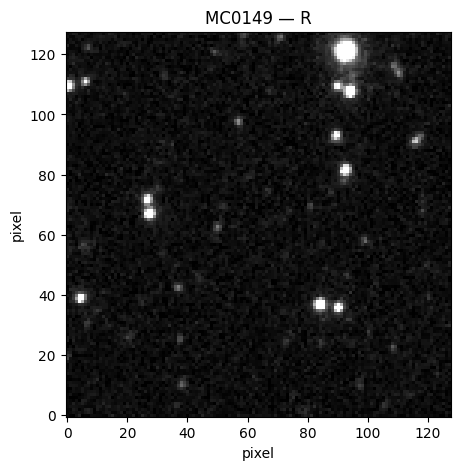

In [3]:
stamp_bytes = cl.create_stamp(
    file_id=int(science_file["id"]), ra=ra, dec=dec,
    size=128, size_unit="pixels", format="fits",
)
with fits.open(BytesIO(stamp_bytes)) as hdul:
    image = next((hdu.data for hdu in hdul if hdu.data is not None), None)
if image is None:
    raise ValueError("O FITS retornado não contém plano de imagem.")
finite_fraction = np.isfinite(image).mean()
print(f"shape={image.shape}, fração de pixels finitos={finite_fraction:.3f}")
lo, hi = np.nanpercentile(image, [5, 99.5])
fig, ax = plt.subplots(figsize=(5, 5))
ax.imshow(image, origin="lower", cmap="gray", vmin=lo, vmax=hi)
ax.set(title=f"{science_file['object_name']} — R", xlabel="pixel", ylabel="pixel")
plt.show()

## RGB opcional

RGB depende de três filtros cobrindo a posição. Tentamos `I/R/G` na mesma coleção; se faltar cobertura, o cutout FITS acima continua válido. A composição Lupton é útil para inspeção, mas seus valores de pixel não substituem fotometria calibrada.
`PIL.Image.open` decodifica o PNG de bytes retornados pela API. Os canais I/R/G são combinados pelo método de Lupton para visualização; compare cores com cautela, pois a escala de exibição não substitui fotometria calibrada.


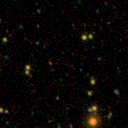

In [4]:
try:
    rgb_bytes = cl.create_rgb_image_by_coordinates(
        collection_id=collection_id, ra=ra, dec=dec, size=128,
        size_unit="pixels", r_filter="I", g_filter="R", b_filter="G",
    )
    rgb = Image.open(BytesIO(rgb_bytes))
    display(rgb)
except Exception as exc:
    print(f"RGB indisponível neste campo: {type(exc).__name__}: {exc}")

## Da inspeção ao dataset

Para cada alvo, registre `object_id`, RA/Dec, `collection_id`, `file_id`, filtro, tamanho, unidade e estado do pedido. Guarde o FITS ou seu caminho no manifest. Para treinamento, verifique cobertura, máscara de pixels, escala, contaminação por vizinhos e distribuições por campo. O notebook 05 constrói esse manifest junto com Gaia e DESI.

**Exercício:** altere o tamanho do cutout e compare a fração de pixels finitos. Qual informação adicional é necessária para misturar imagens de campos ou instrumentos diferentes?